# Sistema de alerta temprana de plagas a partir de datos climáticos

**Trabajo Práctico Integrador — Inteligencia Artificial — Universidad de Palermo**
**Alumna:** Yamileth Cabrera · **Fecha:** noviembre de 2026

Este notebook predice el **nivel de riesgo diario de la chicharrita del maíz** (*Dalbulus maidis*) en Pergamino (Buenos Aires) usando datos climáticos de NASA POWER, y compara tres técnicas vistas en la materia:

1. **Lógica difusa** (Módulo 5): conocimiento experto con transiciones graduales, sin entrenamiento.
2. **Árbol de decisión** (Módulo 6): aprende reglas a partir de los datos.
3. **Red neuronal MLP** (Módulos 8 y 9): aprende una función no lineal con backpropagation.

El sistema experto en Prolog (Módulo 4) está en `prolog/sistema_experto_plagas.pl`.

**Cómo ejecutarlo:** en local, desde la carpeta `notebooks/` del repositorio (lee `datos/crudos/nasa_power_test.csv`). En Google Colab, subir `nasa_power_test.csv` al panel de archivos o completar `URL_CSV_REPO`, y ejecutar *Entorno de ejecución → Ejecutar todas*. Si no encuentra el CSV, lo descarga directamente de la API de NASA POWER.

## 1. Librerías

In [1]:
# scikit-fuzzy no viene instalado en Colab
%pip install -q scikit-fuzzy

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
from io import StringIO

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker
import requests

import skfuzzy as fuzz
from skfuzzy import control as ctrl

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

plt.rcParams['figure.dpi'] = 110
# Rutas: si el notebook corre dentro del repositorio (carpeta notebooks/) usa la estructura del repo;
# si corre suelto (por ejemplo en Colab) trabaja en la carpeta actual
RAIZ = '..' if os.path.isdir(os.path.join('..', 'datos')) else '.'
FIG = os.path.join(RAIZ, 'figuras')
PROCESADOS = os.path.join(RAIZ, 'datos', 'procesados')
RESULTADOS = os.path.join(RAIZ, 'resultados')
for carpeta in (FIG, PROCESADOS, RESULTADOS):
    os.makedirs(carpeta, exist_ok=True)

CLASES = ['Bajo', 'Medio', 'Alto']
COLORES = ['#2e9e5b', '#f0a202', '#d64545']
SEMILLA = 42

## 2. Datos: NASA POWER

Datos diarios 2020–2024 para Pergamino (lat −33,93, lon −60,53): temperatura media, máxima y mínima, precipitación, humedad relativa y radiación solar. El archivo del repositorio es la misma consulta a la API.

In [3]:
CANDIDATOS = [os.path.join(RAIZ, 'datos', 'crudos', 'nasa_power_test.csv'), 'nasa_power_test.csv']
ARCHIVO_CSV = next((c for c in CANDIDATOS if os.path.exists(c)), CANDIDATOS[0])
URL_CSV_REPO = ''   # opcional: link "raw" del CSV en GitHub
URL_API = ('https://power.larc.nasa.gov/api/temporal/daily/point?'
           'parameters=T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,ALLSKY_SFC_SW_DWN'
           '&community=AG&longitude=-60.53&latitude=-33.93'
           '&start=20200101&end=20241231&format=CSV')

if os.path.exists(ARCHIVO_CSV):
    texto = open(ARCHIVO_CSV, encoding='utf-8').read()
    origen = 'archivo local'
else:
    url = URL_CSV_REPO or URL_API
    respuesta = requests.get(url, timeout=120)
    respuesta.raise_for_status()
    texto = respuesta.text
    origen = url

# El CSV trae un encabezado descriptivo que termina en '-END HEADER-'
lineas = texto.splitlines()
inicio = next(i for i, l in enumerate(lineas) if '-END HEADER-' in l) + 1
df = pd.read_csv(StringIO('\n'.join(lineas[inicio:])))

# Fecha a partir de año + día del año, y -999 (dato faltante de NASA) a NaN
df['FECHA'] = pd.to_datetime(df['YEAR'].astype(str) + df['DOY'].astype(str).str.zfill(3), format='%Y%j')
df['MES'] = df['FECHA'].dt.month
VARS_CLIMA = ['T2M', 'T2M_MAX', 'T2M_MIN', 'PRECTOTCORR', 'RH2M', 'ALLSKY_SFC_SW_DWN']
df[VARS_CLIMA] = df[VARS_CLIMA].replace(-999, np.nan)

print(f'Origen: {origen}')
print(f'{len(df)} días, del {df.FECHA.min().date()} al {df.FECHA.max().date()}')
print(f'Valores faltantes: {int(df[VARS_CLIMA].isna().sum().sum())}')
df[VARS_CLIMA].describe().round(1)

Origen: archivo local
1827 días, del 2020-01-01 al 2024-12-31
Valores faltantes: 0


,T2M,T2M_MAX,T2M_MIN,PRECTOTCORR,RH2M,ALLSKY_SFC_SW_DWN
count,1827.0,1827.0,1827.0,1827.0,1827.0,1827.0
mean,17.5,24.7,11.0,2.2,65.7,17.9
std,6.8,7.3,6.3,6.9,14.6,8.6
min,1.0,5.7,-3.9,0.0,22.4,1.2
25%,12.0,19.0,6.0,0.0,55.5,11.2
50%,17.5,24.6,10.9,0.0,66.7,16.7
75%,22.7,30.2,15.9,0.5,77.2,25.4
max,35.3,43.8,28.9,89.8,96.4,34.2


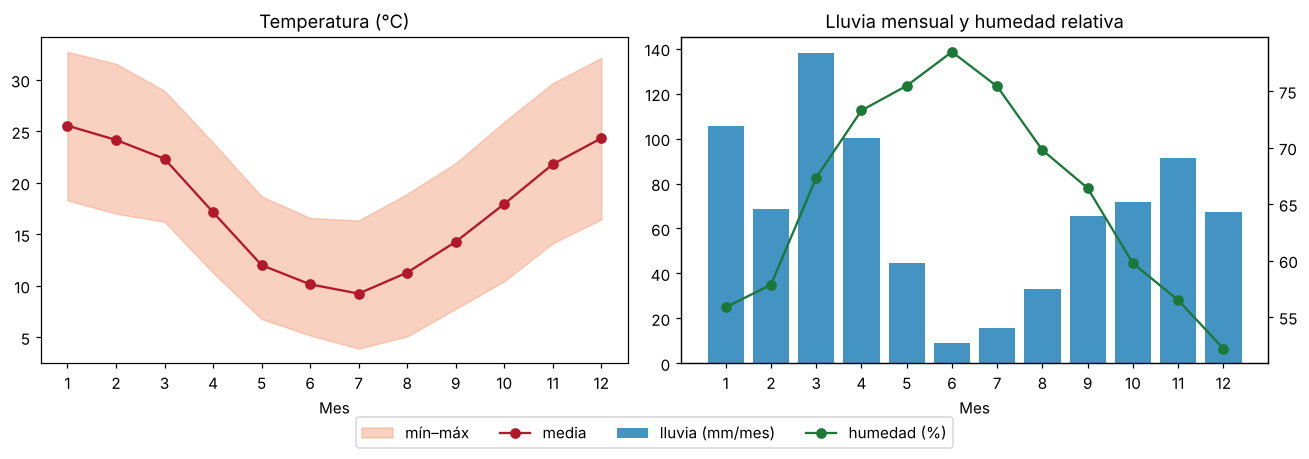

In [4]:
# Clima promedio por mes: muestra la estacionalidad que después aparece en el riesgo
mensual = df.groupby('MES')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].fill_between(range(1, 13), mensual.T2M_MIN.mean(), mensual.T2M_MAX.mean(), color='#f4a582', alpha=.5, label='mín–máx')
ax[0].plot(range(1, 13), mensual.T2M.mean(), 'o-', color='#b2182b', label='media')
ax[0].set(title='Temperatura (°C)', xlabel='Mes', xticks=range(1, 13))
ax[1].bar(range(1, 13), mensual.PRECTOTCORR.sum() / df.YEAR.nunique(), color='#4393c3', label='lluvia (mm/mes)')
ax2 = ax[1].twinx(); ax2.plot(range(1, 13), mensual.RH2M.mean(), 'o-', color='#1b7837', label='humedad (%)')
ax[1].set(title='Lluvia mensual y humedad relativa', xlabel='Mes', xticks=range(1, 13))
fig.legend(loc='lower center', ncol=4, bbox_to_anchor=(.5, -.05))
plt.tight_layout(); plt.savefig(f'{FIG}/clima_mensual.png', bbox_inches='tight'); plt.show()

## 3. Variables derivadas y variable objetivo

No existe un registro público diario de la plaga para esta zona, así que **el riesgo se etiqueta con reglas basadas en la biología del insecto** (INTA, Aapresid). Se usan cuatro factores favorables:

| Factor | Condición | Por qué |
|---|---|---|
| Temperatura | máxima entre 26 y 32 °C y mínima ≥ 5 °C | rango óptimo de desarrollo; el frío frena su actividad |
| Humedad | humedad relativa ≥ 65 % | ambientes húmedos favorecen su multiplicación |
| Lluvia reciente | lluvia acumulada en 7 días ≥ 10 mm | el cultivo y las malezas verdes le dan refugio |
| Invierno previo benigno | el invierno anterior (jun–ago) no tuvo ningún día con mínima < −2 °C | los adultos sobreviven al invierno (causa del brote 2023/24) |

**Riesgo = cantidad de factores cumplidos:** 0–1 → Bajo, 2 → Medio, 3–4 → Alto.

El factor invierno se aplica a la campaña siguiente: de septiembre a mayo se mira el último invierno ya terminado; durante junio–agosto (el invierno en curso) no se cuenta. Los días de enero a mayo de 2020 se descartan porque los datos no incluyen el invierno de 2019.

In [5]:
# Variables derivadas
df['AMPLITUD_TERMICA'] = df['T2M_MAX'] - df['T2M_MIN']
df['PRECIP_7D'] = df['PRECTOTCORR'].rolling(7, min_periods=7).sum()

# Heladas fuertes (mínima < -2 °C) en el invierno de cada año
invierno = df[df.MES.isin([6, 7, 8])]
heladas_por_invierno = (invierno.T2M_MIN < -2).groupby(invierno.YEAR).sum()
print('Heladas fuertes por invierno:', heladas_por_invierno.to_dict())

# Campaña: de septiembre a agosto. Su invierno previo es el del año en que empieza
df['ANIO_INVIERNO'] = np.where(df.MES >= 9, df.YEAR, df.YEAR - 1)
df['CAMPANIA'] = df['ANIO_INVIERNO'].astype(str) + '/' + (df['ANIO_INVIERNO'] + 1).astype(str).str[-2:]
df['HELADAS_INVIERNO'] = df['ANIO_INVIERNO'].map(heladas_por_invierno)
en_invierno = df.MES.isin([6, 7, 8])
df['INVIERNO_BENIGNO'] = ((df.HELADAS_INVIERNO == 0) & ~en_invierno).astype(int)

# Se descartan los días sin invierno previo conocido (ene–may 2020) y sin 7 días de lluvia acumulada
df = df[en_invierno | df.HELADAS_INVIERNO.notna()].dropna(subset=['PRECIP_7D'] + VARS_CLIMA).reset_index(drop=True)
print(f'Días utilizables: {len(df)} ({df.FECHA.min().date()} a {df.FECHA.max().date()})')

Heladas fuertes por invierno: {2020: 2, 2021: 2, 2022: 0, 2023: 0, 2024: 5}
Días utilizables: 1675 (2020-06-01 a 2024-12-31)


In [6]:
def factores_favorables(t_max, t_min, humedad, lluvia_7d, invierno_benigno):
    """Cuenta cuántos de los 4 factores favorables a la plaga se cumplen."""
    temperatura = (26 <= t_max <= 32) and (t_min >= 5)
    humeda = humedad >= 65
    lluviosa = lluvia_7d >= 10
    return int(temperatura) + int(humeda) + int(lluviosa) + int(invierno_benigno == 1)

def clasificar_riesgo(factores):
    """0-1 factores: Bajo (0) · 2: Medio (1) · 3-4: Alto (2)"""
    return 0 if factores <= 1 else (1 if factores == 2 else 2)

df['FACTORES'] = [factores_favorables(*fila) for fila in
                  df[['T2M_MAX', 'T2M_MIN', 'RH2M', 'PRECIP_7D', 'INVIERNO_BENIGNO']].itertuples(index=False)]
df['RIESGO'] = df['FACTORES'].map(clasificar_riesgo)

conteo = df['RIESGO'].value_counts().sort_index()
for clase, n in conteo.items():
    print(f'{CLASES[clase]:>5}: {n:4d} días ({n / len(df):.0%})')

 Bajo:  953 días (57%)
Medio:  460 días (27%)
 Alto:  262 días (16%)


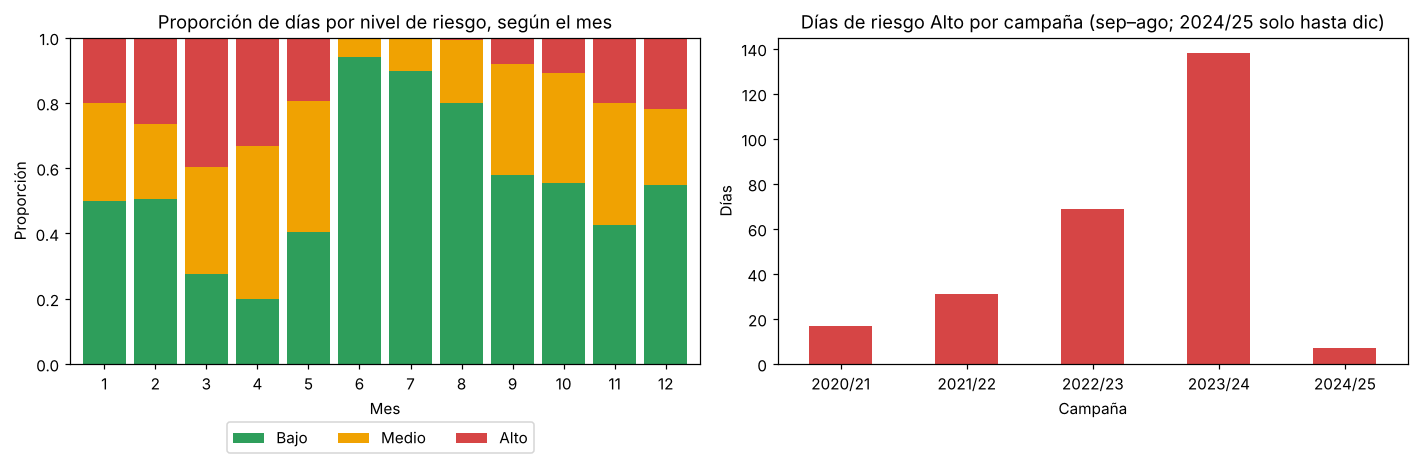

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
por_mes = pd.crosstab(df.MES, df.RIESGO, normalize='index').reindex(columns=[0, 1, 2], fill_value=0)
por_mes.plot(kind='bar', stacked=True, color=COLORES, ax=ax[0], width=.85, legend=False)
ax[0].set(title='Proporción de días por nivel de riesgo, según el mes', xlabel='Mes', ylabel='Proporción')
ax[0].tick_params(axis='x', rotation=0)
campanias = sorted(c for c in df.CAMPANIA.unique() if c >= '2020')   # 2019/20 solo tiene jun–ago
alto_campania = df[df.RIESGO == 2].groupby('CAMPANIA').size().reindex(campanias, fill_value=0)
alto_campania.plot(kind='bar', color=COLORES[2], ax=ax[1])
ax[1].set(title='Días de riesgo Alto por campaña (sep–ago; 2024/25 solo hasta dic)', xlabel='Campaña', ylabel='Días')
ax[1].tick_params(axis='x', rotation=0)
fig.legend(CLASES, loc='lower center', ncol=3, bbox_to_anchor=(.27, -.06))
plt.tight_layout(); plt.savefig(f'{FIG}/riesgo_por_mes_y_campania.png', bbox_inches='tight'); plt.show()

## 4. Entrenamiento y prueba

Como son datos en el tiempo, **no se mezclan días al azar**: se entrena con junio 2020 – diciembre 2023 y se prueba con todo 2024, como si el modelo se usara en un año nuevo. La normalización Min-Max se ajusta solo con entrenamiento y se usa solo en la red neuronal.

In [8]:
FEATURES = ['T2M', 'T2M_MAX', 'T2M_MIN', 'PRECTOTCORR', 'RH2M', 'ALLSKY_SFC_SW_DWN',
            'AMPLITUD_TERMICA', 'PRECIP_7D', 'INVIERNO_BENIGNO']

entrenamiento = df.FECHA.dt.year < 2024
X_train, X_test = df.loc[entrenamiento, FEATURES], df.loc[~entrenamiento, FEATURES]
y_train, y_test = df.loc[entrenamiento, 'RIESGO'], df.loc[~entrenamiento, 'RIESGO']

escalador = MinMaxScaler().fit(X_train)
X_train_esc, X_test_esc = escalador.transform(X_train), escalador.transform(X_test)

print(f'Entrenamiento: {len(X_train)} días · Prueba (2024): {len(X_test)} días')
print('Clases en prueba:', {CLASES[k]: int(v) for k, v in y_test.value_counts().sort_index().items()})
print(f'Referencia: predecir siempre la clase más frecuente da accuracy {y_test.value_counts(normalize=True).max():.2f}')

def evaluar(nombre, y_pred):
    print(f'{nombre} — accuracy {accuracy_score(y_test, y_pred):.3f} · F1 macro {f1_score(y_test, y_pred, average="macro"):.3f}')
    print(classification_report(y_test, y_pred, labels=[0, 1, 2], target_names=CLASES, digits=3, zero_division=0))

Entrenamiento: 1309 días · Prueba (2024): 366 días
Clases en prueba: {'Bajo': 179, 'Medio': 104, 'Alto': 83}
Referencia: predecir siempre la clase más frecuente da accuracy 0.49


## 5. Enfoque 1: Lógica difusa (Mamdani)

Usa el **mismo conocimiento experto** que las reglas, pero con conjuntos difusos: un día de 25,5 °C no es "nada favorable", es *casi* favorable. Cada conjunto vale 0,5 justo en el umbral de la regla nítida.

- **Entradas:** temperatura máxima, temperatura mínima, humedad, lluvia de 7 días e invierno previo benigno (0 = no, 1 = sí).
- **Reglas:** una por cada combinación de los 4 factores (16 reglas). El consecuente depende de cuántos factores son favorables, igual que en la etiqueta.
- **Inferencia:** AND = mínimo, OR = máximo, agregación por máximo y defuzzificación por centroide.

In [9]:
t_max = ctrl.Antecedent(np.arange(-5, 45.1, 0.1), 't_max')
t_min = ctrl.Antecedent(np.arange(-10, 30.1, 0.1), 't_min')
humedad = ctrl.Antecedent(np.arange(0, 100.1, 0.5), 'humedad')
lluvia = ctrl.Antecedent(np.arange(0, 200.1, 0.5), 'lluvia_7d')
invierno = ctrl.Antecedent(np.arange(0, 1.01, 0.01), 'invierno_benigno')
riesgo = ctrl.Consequent(np.arange(0, 100.1, 0.5), 'riesgo')

# Cada término "favorable" vale 0,5 en el umbral de la regla nítida; "desfavorable" es su complemento
t_max['favorable'] = fuzz.trapmf(t_max.universe, [24, 28, 30, 34])
t_min['templada'] = fuzz.trapmf(t_min.universe, [3, 7, 30, 30])
humedad['alta'] = fuzz.trapmf(humedad.universe, [55, 75, 100, 100])
lluvia['abundante'] = fuzz.trapmf(lluvia.universe, [5, 15, 200, 200])
invierno['benigno'] = invierno.universe.copy()   # dato 0/1: la pertenencia es el propio valor
for var, termino, opuesto in [(t_max, 'favorable', 'desfavorable'), (t_min, 'templada', 'fria'),
                              (humedad, 'alta', 'baja'), (lluvia, 'abundante', 'escasa'),
                              (invierno, 'benigno', 'no_benigno')]:
    var[opuesto] = 1 - var[termino].mf

riesgo['bajo'] = fuzz.trapmf(riesgo.universe, [0, 0, 20, 40])
riesgo['medio'] = fuzz.trimf(riesgo.universe, [30, 50, 70])
riesgo['alto'] = fuzz.trapmf(riesgo.universe, [60, 80, 100, 100])

# Los 4 factores, cada uno en versión favorable / desfavorable
factor_temp = (t_max['favorable'] & t_min['templada'], t_max['desfavorable'] | t_min['fria'])
factor_hum = (humedad['alta'], humedad['baja'])
factor_lluvia = (lluvia['abundante'], lluvia['escasa'])
factor_invierno = (invierno['benigno'], invierno['no_benigno'])

reglas = []
for a in (0, 1):
    for b in (0, 1):
        for c in (0, 1):
            for d in (0, 1):
                favorables = 4 - (a + b + c + d)          # índice 0 = favorable
                consecuente = 'bajo' if favorables <= 1 else ('medio' if favorables == 2 else 'alto')
                antecedente = factor_temp[a] & factor_hum[b] & factor_lluvia[c] & factor_invierno[d]
                reglas.append(ctrl.Rule(antecedente, riesgo[consecuente]))

sistema_difuso = ctrl.ControlSystemSimulation(ctrl.ControlSystem(reglas))
print(f'Sistema difuso con {len(reglas)} reglas.')

Sistema difuso con 16 reglas.


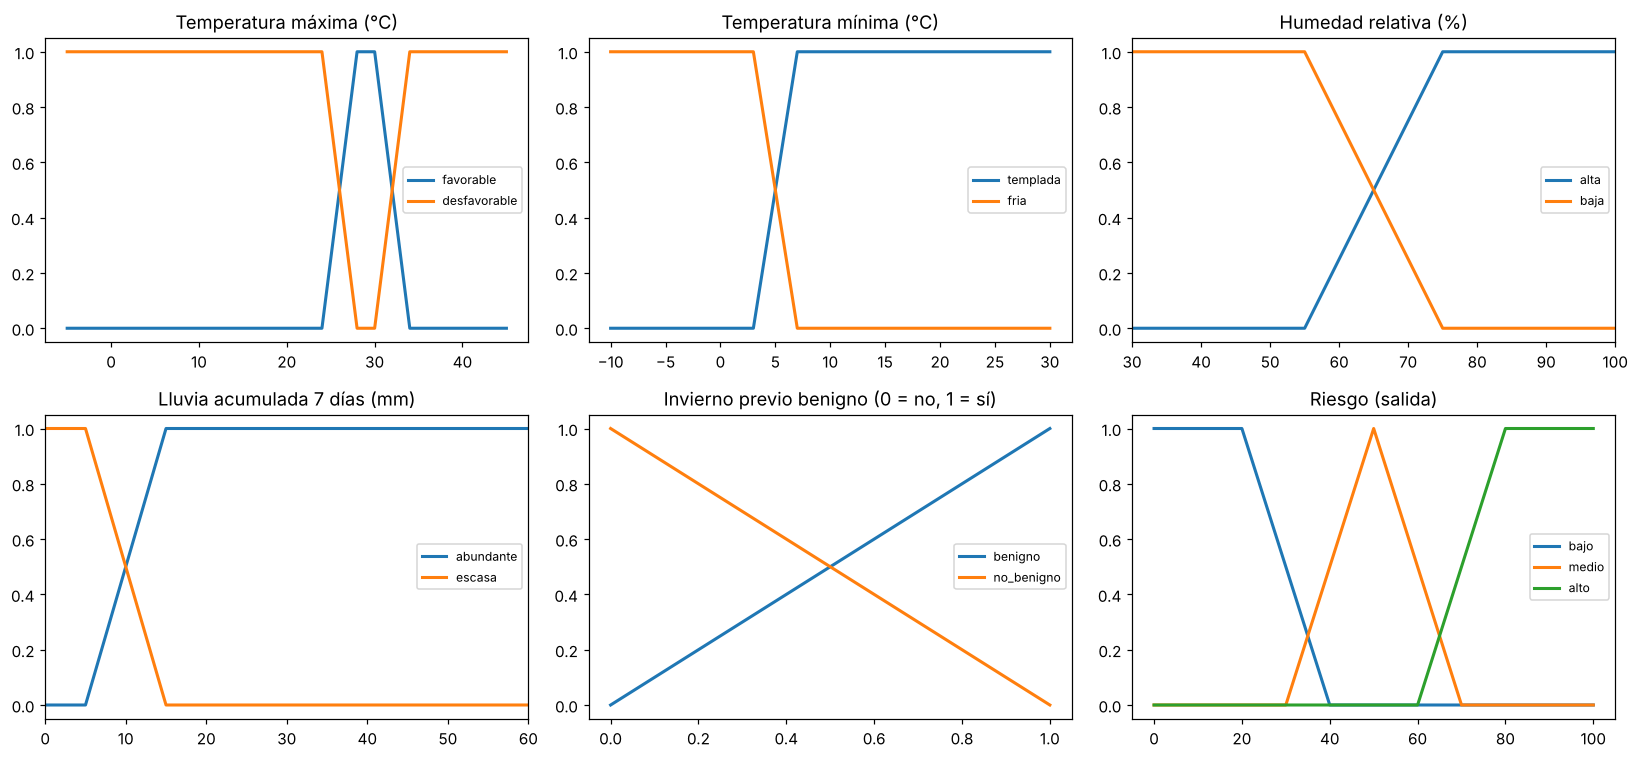

In [10]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for eje, var, titulo in zip(ax.flat, [t_max, t_min, humedad, lluvia, invierno, riesgo],
                            ['Temperatura máxima (°C)', 'Temperatura mínima (°C)', 'Humedad relativa (%)',
                             'Lluvia acumulada 7 días (mm)', 'Invierno previo benigno (0 = no, 1 = sí)',
                             'Riesgo (salida)']):
    for termino in var.terms:
        eje.plot(var.universe, var[termino].mf, label=termino, linewidth=2)
    eje.set_title(titulo); eje.legend(fontsize=8); eje.set_ylim(-.05, 1.05)
ax[0, 2].set_xlim(30, 100); ax[1, 0].set_xlim(0, 60)
plt.tight_layout(); plt.savefig(f'{FIG}/funciones_pertenencia.png', bbox_inches='tight'); plt.show()

In [11]:
def riesgo_difuso(fila):
    sistema_difuso.input['t_max'] = np.clip(fila.T2M_MAX, -5, 45)
    sistema_difuso.input['t_min'] = np.clip(fila.T2M_MIN, -10, 30)
    sistema_difuso.input['humedad'] = np.clip(fila.RH2M, 0, 100)
    sistema_difuso.input['lluvia_7d'] = np.clip(fila.PRECIP_7D, 0, 200)
    sistema_difuso.input['invierno_benigno'] = fila.INVIERNO_BENIGNO
    sistema_difuso.compute()
    return sistema_difuso.output['riesgo']

def a_clase(valor):
    """Corte del valor defuzzificado (0-100) en las tres clases."""
    return 0 if valor < 35 else (1 if valor < 65 else 2)

df_test = df.loc[~entrenamiento]
valor_difuso = np.array([riesgo_difuso(f) for f in df_test.itertuples()])
y_pred_difuso = np.array([a_clase(v) for v in valor_difuso])
evaluar('Lógica difusa', y_pred_difuso)

Lógica difusa — accuracy 0.940 · F1 macro 0.936
              precision    recall  f1-score   support

        Bajo      0.971     0.950     0.960       179
       Medio      0.880     0.913     0.896       104
        Alto      0.952     0.952     0.952        83

    accuracy                          0.940       366
   macro avg      0.934     0.938     0.936       366
weighted avg      0.941     0.940     0.940       366



05/03/2024: máx 25.9 °C, mín 11.6 °C, humedad 61 %, lluvia 7 días 24.4 mm, invierno previo benigno: sí
Valor defuzzificado: 66.8 → riesgo Alto  (regla nítida: Medio)


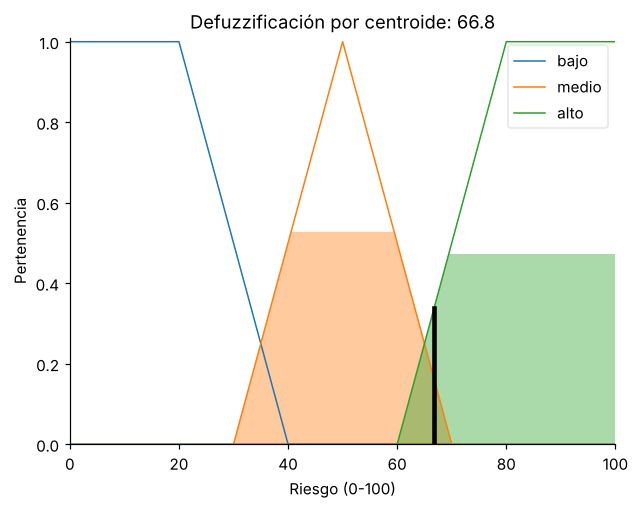

In [12]:
# Ejemplo: un día con máxima apenas debajo de 26 °C. La regla nítida no cuenta el factor temperatura;
# la lógica difusa lo cuenta "casi" completo y por eso sube el riesgo.
ejemplo = df_test[df_test.FECHA == '2024-03-05'].iloc[0]
valor = riesgo_difuso(ejemplo)
print(f'05/03/2024: máx {ejemplo.T2M_MAX:.1f} °C, mín {ejemplo.T2M_MIN:.1f} °C, humedad {ejemplo.RH2M:.0f} %, '
      f'lluvia 7 días {ejemplo.PRECIP_7D:.1f} mm, invierno previo benigno: {"sí" if ejemplo.INVIERNO_BENIGNO else "no"}')
print(f'Valor defuzzificado: {valor:.1f} → riesgo {CLASES[a_clase(valor)]}  (regla nítida: {CLASES[ejemplo.RIESGO]})')
riesgo.view(sim=sistema_difuso)
plt.title(f'Defuzzificación por centroide: {valor:.1f}'); plt.ylabel('Pertenencia'); plt.xlabel('Riesgo (0-100)')
plt.savefig(f'{FIG}/ejemplo_defuzzificacion.png', bbox_inches='tight'); plt.show()

## 6. Enfoque 2: Árbol de decisión

Árbol CART con índice Gini. La profundidad se limita a 4 para evitar sobreajuste y para que el árbol se pueda leer.

In [13]:
arbol = DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=SEMILLA)
arbol.fit(X_train, y_train)
y_pred_arbol = arbol.predict(X_test)
evaluar('Árbol de decisión', y_pred_arbol)

Árbol de decisión — accuracy 0.940 · F1 macro 0.936
              precision    recall  f1-score   support

        Bajo      0.988     0.933     0.960       179
       Medio      0.887     0.904     0.895       104
        Alto      0.912     1.000     0.954        83

    accuracy                          0.940       366
   macro avg      0.929     0.946     0.936       366
weighted avg      0.942     0.940     0.940       366



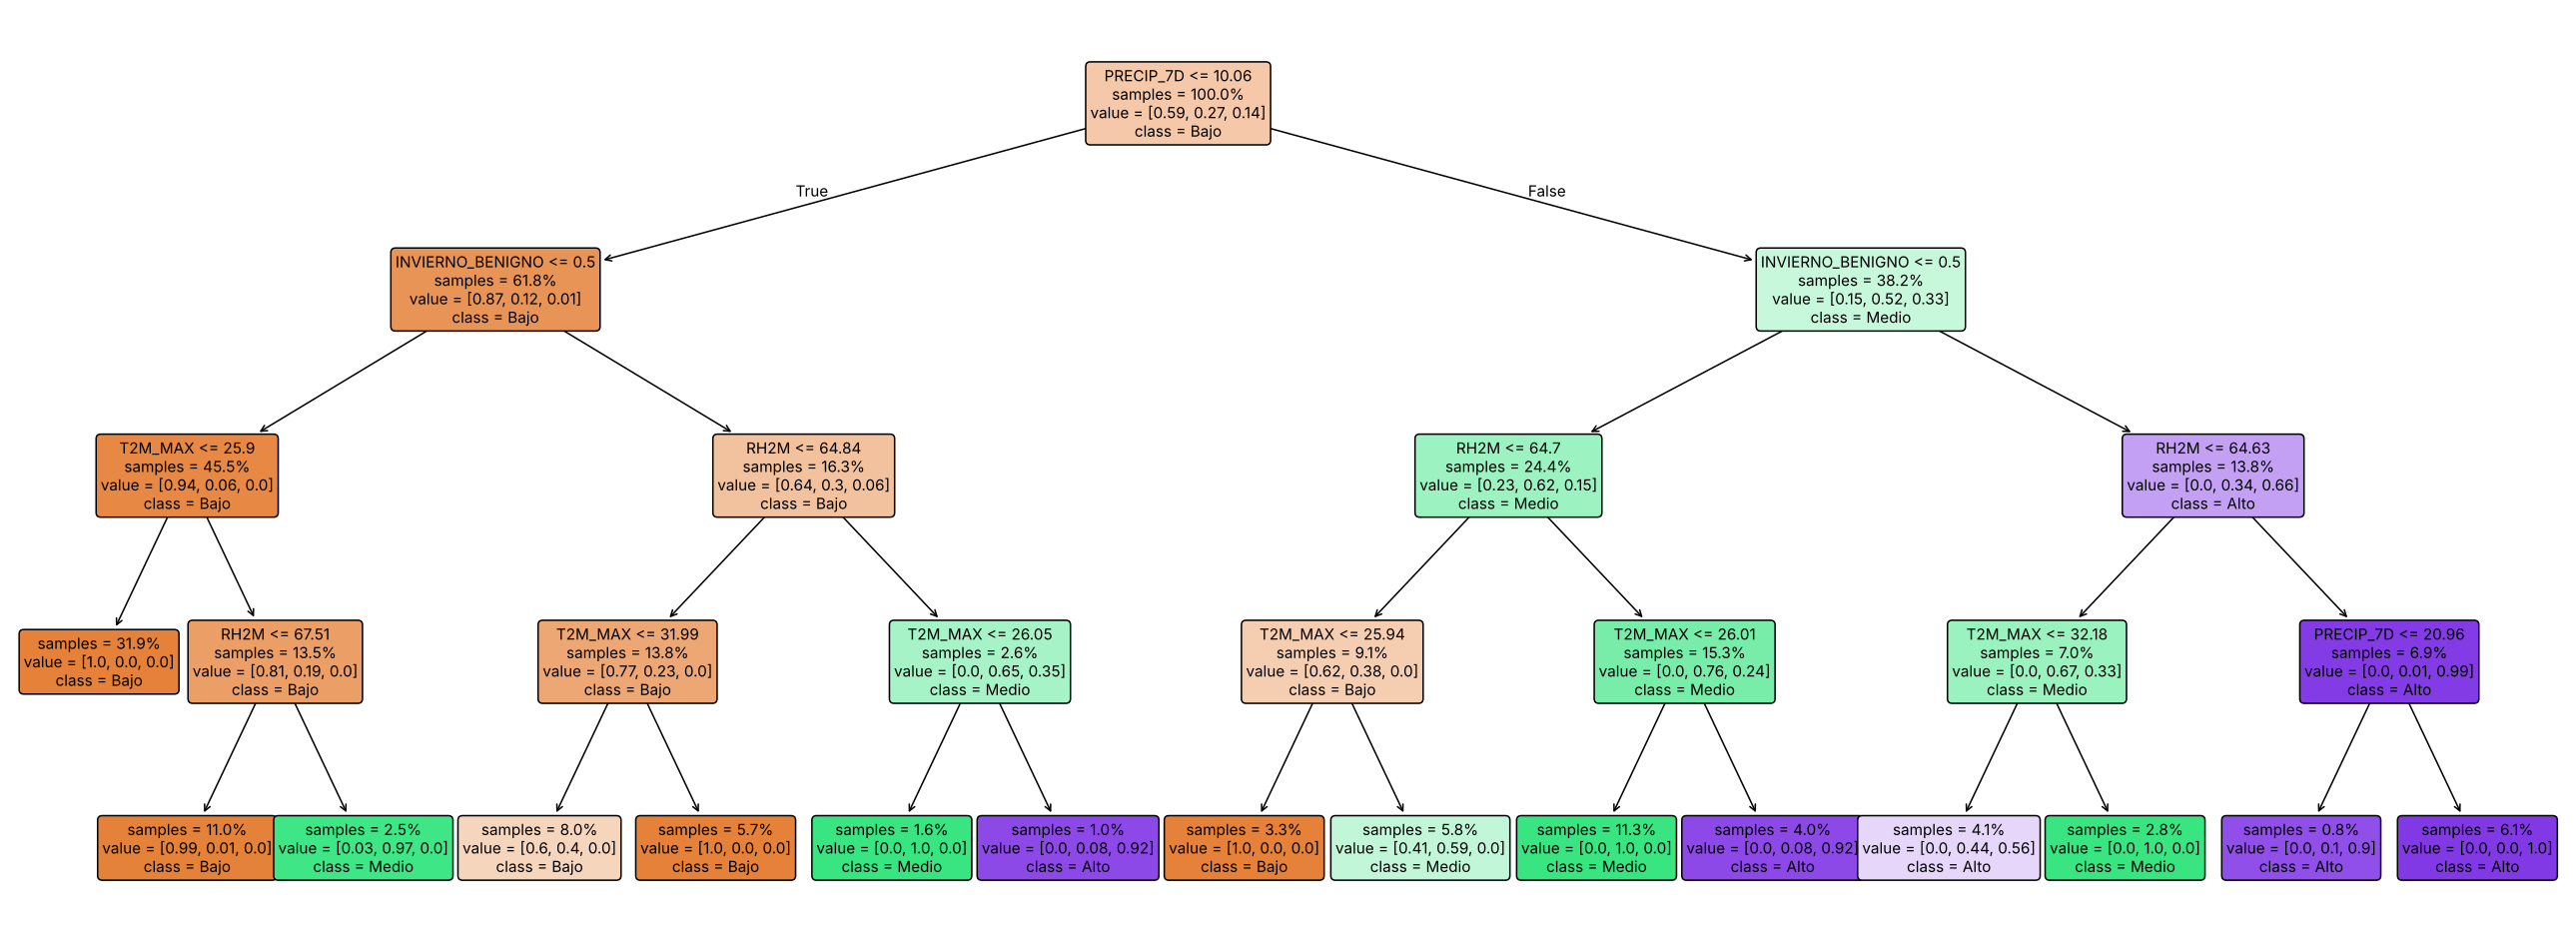

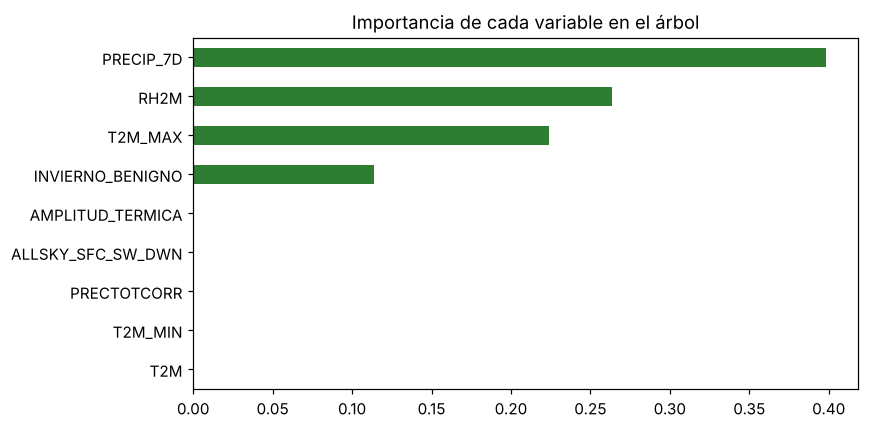

In [14]:
fig, ax = plt.subplots(figsize=(30, 11))
plot_tree(arbol, feature_names=FEATURES, class_names=CLASES, filled=True, rounded=True,
          impurity=False, proportion=True, precision=2, fontsize=10, ax=ax)
plt.savefig(f'{FIG}/arbol_decision.png', bbox_inches='tight'); plt.show()

importancia = pd.Series(arbol.feature_importances_, index=FEATURES).sort_values()
importancia.plot(kind='barh', color='#2e7d32', figsize=(8, 4), title='Importancia de cada variable en el árbol')
plt.tight_layout(); plt.savefig(f'{FIG}/importancia_variables.png', bbox_inches='tight'); plt.show()

## 7. Enfoque 3: Red neuronal MLP

Perceptrón multicapa: 9 entradas → 16 neuronas (ReLU) → 8 neuronas (ReLU) → 3 salidas (softmax). Se entrena con backpropagation usando el optimizador Adam, que es una variante del descenso por gradiente.

Épocas: 881 · pérdida final: 0.2882
Red neuronal MLP — accuracy 0.842 · F1 macro 0.826
              precision    recall  f1-score   support

        Bajo      0.857     0.939     0.896       179
       Medio      0.767     0.635     0.695       104
        Alto      0.881     0.892     0.886        83

    accuracy                          0.842       366
   macro avg      0.835     0.822     0.826       366
weighted avg      0.837     0.842     0.837       366



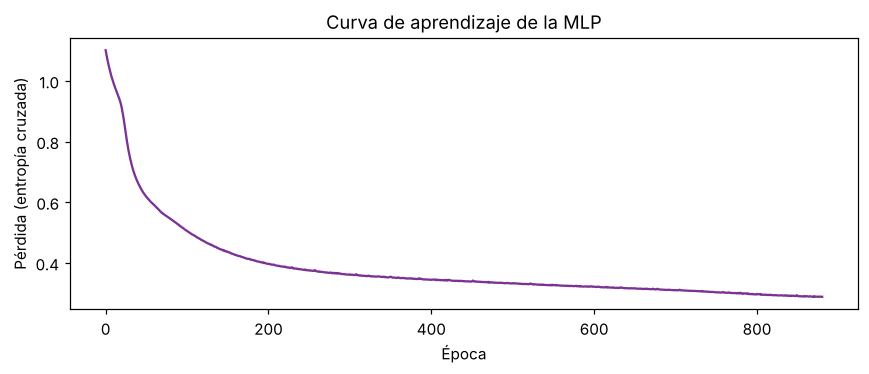

In [15]:
mlp = MLPClassifier(hidden_layer_sizes=(16, 8), activation='relu', solver='adam',
                    learning_rate_init=0.001, max_iter=2000, random_state=SEMILLA)
mlp.fit(X_train_esc, y_train)
y_pred_mlp = mlp.predict(X_test_esc)
print(f'Épocas: {mlp.n_iter_} · pérdida final: {mlp.loss_:.4f}')
evaluar('Red neuronal MLP', y_pred_mlp)

plt.figure(figsize=(8, 3.5))
plt.plot(mlp.loss_curve_, color='#7b3294')
plt.title('Curva de aprendizaje de la MLP'); plt.xlabel('Época'); plt.ylabel('Pérdida (entropía cruzada)')
plt.tight_layout(); plt.savefig(f'{FIG}/curva_aprendizaje_mlp.png', bbox_inches='tight'); plt.show()

## 8. Comparación

,Accuracy,F1 macro,Recall Alto
Lógica difusa,0.940,0.936,0.952
Árbol de decisión,0.940,0.936,1.000
Red neuronal MLP,0.842,0.826,0.892


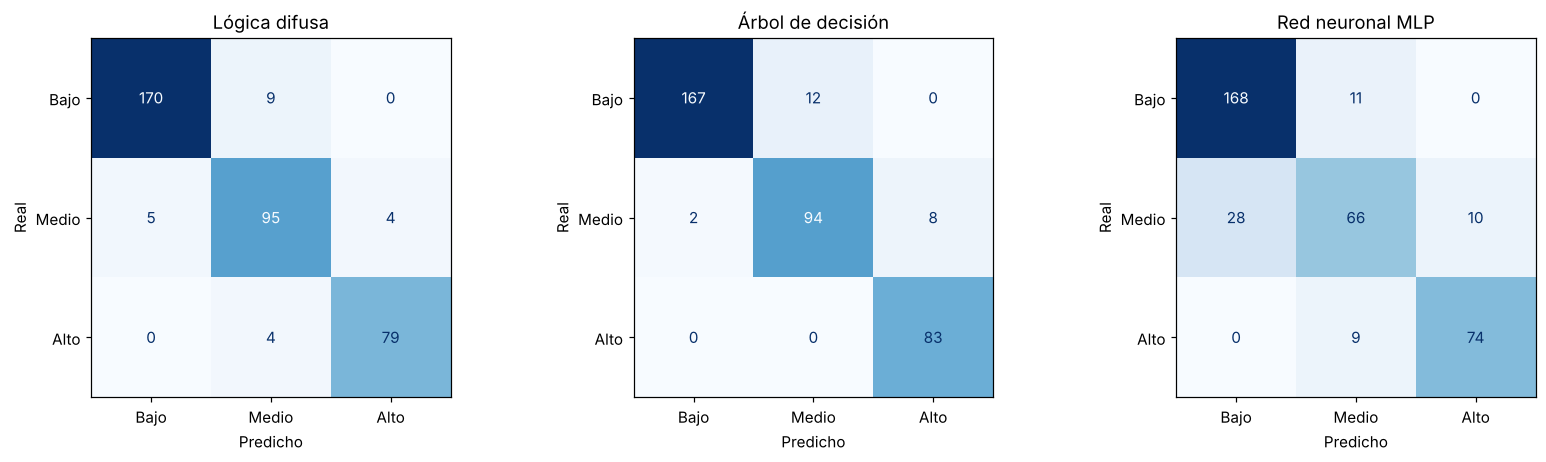

In [16]:
predicciones = {'Lógica difusa': y_pred_difuso, 'Árbol de decisión': y_pred_arbol, 'Red neuronal MLP': y_pred_mlp}
resultados = pd.DataFrame({
    nombre: {'Accuracy': accuracy_score(y_test, p),
             'F1 macro': f1_score(y_test, p, average='macro'),
             'Recall Alto': (p[y_test.values == 2] == 2).mean()}
    for nombre, p in predicciones.items()}).T.round(3)
display(resultados)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
for eje, (nombre, p) in zip(ax, predicciones.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p, labels=[0, 1, 2]), display_labels=CLASES).plot(
        ax=eje, cmap='Blues', colorbar=False)
    eje.set_title(nombre); eje.set_xlabel('Predicho'); eje.set_ylabel('Real')
plt.tight_layout(); plt.savefig(f'{FIG}/matrices_confusion.png', bbox_inches='tight'); plt.show()

### El riesgo a lo largo de 2024 y por campaña

El gráfico muestra, día por día, el riesgo real (según las reglas) y lo que predice cada modelo. Así se ve **en qué momentos del año se equivocan**. La tabla resume cada campaña: cuántos días de riesgo Alto tuvo y cuándo apareció el primero, que sería la primera alerta del sistema.

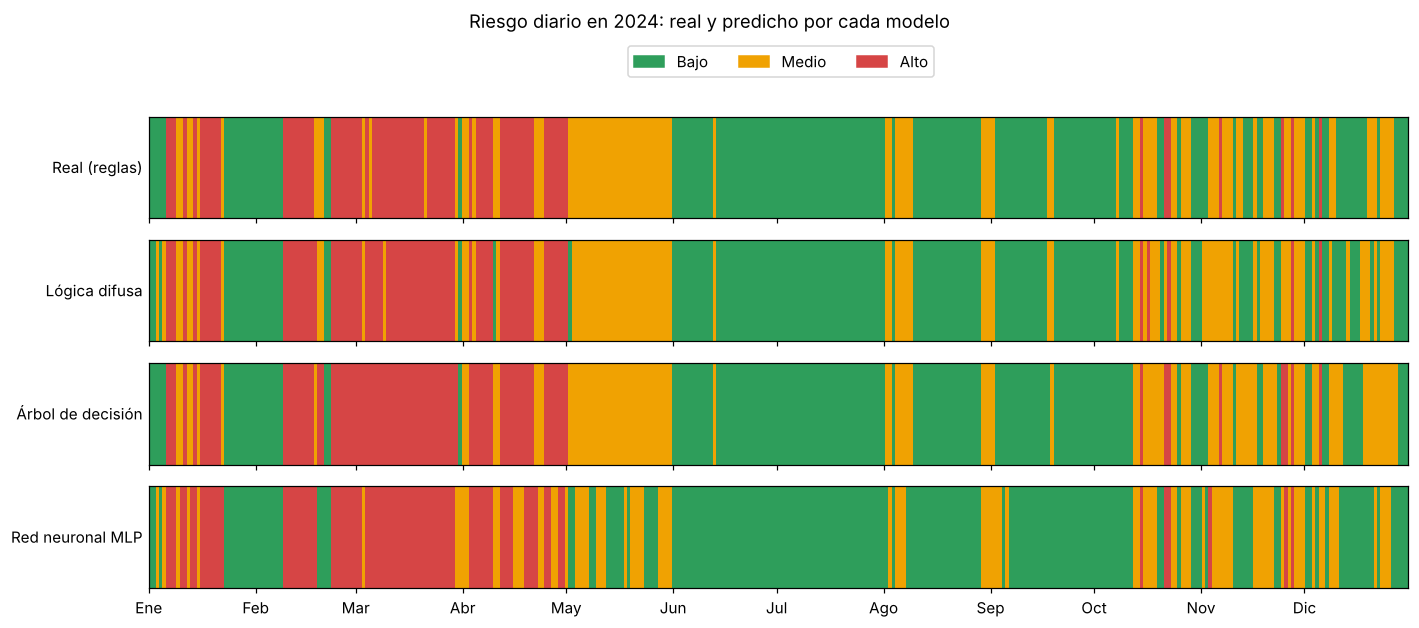

,Días Alto,Primer día Alto,Heladas fuertes del invierno previo
CAMPANIA,,,
2020/21,17,30/09/2020,2
2021/22,31,03/11/2021,2
2022/23,69,24/10/2022,0
2023/24,138,03/09/2023,0
2024/25,7,15/10/2024,5


In [17]:
fig, ax = plt.subplots(4, 1, figsize=(13, 5.2), sharex=True)
series = [('Real (reglas)', y_test.values)] + list(predicciones.items())
cmap = matplotlib.colors.ListedColormap(COLORES)
for eje, (nombre, valores) in zip(ax, series):
    eje.imshow(np.array(valores)[None, :], aspect='auto', cmap=cmap, vmin=0, vmax=2,
               extent=[mdates.date2num(df_test.FECHA.min()), mdates.date2num(df_test.FECHA.max()), 0, 1])
    eje.set_yticks([]); eje.set_ylabel(nombre, rotation=0, ha='right', va='center', fontsize=10)
ax[-1].xaxis.set_major_locator(mdates.MonthLocator()); MESES = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
ax[-1].xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda x, _: MESES[mdates.num2date(x).month - 1]))
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORES]
fig.legend(handles, CLASES, loc='upper center', ncol=3, bbox_to_anchor=(.55, 1.04))
fig.suptitle('Riesgo diario en 2024: real y predicho por cada modelo', y=1.09)
plt.tight_layout(); plt.savefig(f'{FIG}/linea_tiempo_2024.png', bbox_inches='tight'); plt.show()

resumen = (df[df.CAMPANIA >= '2020'].groupby('CAMPANIA')
           .apply(lambda g: pd.Series({'Días Alto': int((g.RIESGO == 2).sum()),
                                       'Primer día Alto': g.loc[g.RIESGO == 2, 'FECHA'].min()})))
resumen['Heladas fuertes del invierno previo'] = [int(heladas_por_invierno.get(int(c[:4]), 0)) for c in resumen.index]
resumen['Primer día Alto'] = resumen['Primer día Alto'].dt.strftime('%d/%m/%Y')
display(resumen)

### Prueba de control: ¿el árbol solo copia la regla?

La etiqueta se construyó con temperatura máxima y mínima, humedad, lluvia de 7 días e invierno benigno, y esas mismas variables entran a los modelos. Por eso un resultado alto es esperable. Para ver si el clima tiene información **más allá de la regla**, se entrena el mismo árbol solo con temperatura media, lluvia del día, radiación solar y amplitud térmica.

In [18]:
SIN_REGLA = ['T2M', 'PRECTOTCORR', 'ALLSKY_SFC_SW_DWN', 'AMPLITUD_TERMICA']
arbol_control = DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, random_state=SEMILLA)
arbol_control.fit(X_train[SIN_REGLA], y_train)
p = arbol_control.predict(X_test[SIN_REGLA])
print(f'Árbol sin las variables de la regla — accuracy {accuracy_score(y_test, p):.3f} · F1 macro {f1_score(y_test, p, average="macro"):.3f}')

Árbol sin las variables de la regla — accuracy 0.585 · F1 macro 0.511


## 9. Conclusiones

| Modelo | Accuracy | F1 macro | Recall clase Alto |
|---|---|---|---|
| Lógica difusa | 0,940 | 0,936 | 0,952 |
| Árbol de decisión | 0,940 | 0,936 | 1,000 |
| Red neuronal MLP | 0,842 | 0,826 | 0,892 |
| *Referencia: siempre la clase más frecuente* | *0,49* | | |

*(Valores obtenidos con la prueba sobre 2024. La tabla calculada está en la sección 8.)*

1. **Los tres enfoques superan ampliamente la referencia.** Además, las reglas marcan la campaña **2023/24**, la del brote real de chicharrita, como la de más días de riesgo Alto (138, el doble que la campaña anterior).
2. **El sistema anticipa la alerta y también la "apaga".** En la campaña 2023/24 el primer día de riesgo Alto fue el 03/09/2023, antes que en cualquier otra campaña. En cambio, después del invierno 2024, que tuvo 5 heladas fuertes, la campaña 2024/25 casi no tiene días Alto (7 hasta diciembre). Esto coincide con lo que se observó en el campo: después de la ola polar de julio de 2024, los conteos de INTA en Pergamino quedaron cerca de cero.
3. **El árbol de decisión y la lógica difusa empatan en accuracy, pero el árbol no deja pasar ningún día de riesgo Alto.** Además **redescubre los umbrales de la regla** (lluvia ≈ 10 mm, máxima ≈ 26 °C, humedad ≈ 65 %), lo que lo hace muy fácil de explicar.
4. **La lógica difusa logra lo mismo sin entrenarse con ningún dato**, solo con el conocimiento experto. Sus diferencias con la etiqueta aparecen en días cercanos a los umbrales. Por ejemplo, el 05/03/2024 tuvo una máxima de 25,9 °C: la regla nítida lo considera "no favorable", pero la lógica difusa lo cuenta casi completo. Esa gradualidad es justamente su ventaja.
5. **La red neuronal es la más débil en este problema**, sobre todo en la clase Medio. La etiqueta está hecha de cortes rectos, y un árbol los representa exactamente, mientras que la red los aproxima con una función suave. También es la menos interpretable.
6. **Limitación principal:** la prueba de control muestra que, sin las variables de la regla, el árbol cae a 0,59, apenas por encima de la referencia de 0,49. Es decir, los modelos **aprenden la regla experta, no la biología de la plaga**. Para que el aprendizaje automático aporte algo nuevo, haría falta entrenar con **capturas reales** de la plaga (por ejemplo, de la red de monitoreo del SENASA o de INTA).

In [19]:
# Exportar dataset etiquetado y resultados (se suben al repositorio junto con el código)
df[['FECHA', 'CAMPANIA'] + FEATURES + ['FACTORES', 'RIESGO']].to_csv(os.path.join(PROCESADOS, 'dataset_riesgo_plagas.csv'), index=False)
resultados.to_csv(os.path.join(RESULTADOS, 'resultados_comparacion.csv'))
print('Guardados:', os.path.join(PROCESADOS, 'dataset_riesgo_plagas.csv'), '·',
      os.path.join(RESULTADOS, 'resultados_comparacion.csv'), '· gráficos en', FIG)

Guardados: ../datos/procesados/dataset_riesgo_plagas.csv · ../resultados/resultados_comparacion.csv · gráficos en ../figuras
